# Topografía de los sitios objetivo y comparación por sitio (v0)
**NASA Space Apps Challenge 2026** · Pendiente de cada sitio de la Luna y Marte, y qué regiones candidatas de la Tierra se le parecen más.

| Cuerpo | Sitios (capa `sitios_v0`) | Modelo de elevación | Escala |
|---|---|---|---|
| Luna, al sur de 75° S | 9 regiones Artemis (polígono), IM-1, IM-2, Chang'e 7 | LRO LOLA `LDEM_75S_240M` (estereográfica polar, 28 MB) | 240 m |
| Luna, resto | Apollo y aterrizajes robóticos (radio de 10 km) | LRO LOLA `LDEM_128` (lectura por filas, como en `topografia_v0`) | ~237 m |
| Marte | 47 Exploration Zones y aterrizajes (radio de 25 km alrededor del centro) | USGS HRSC–MOLA Blended DEM 200 m v2 (lectura por ventanas) | 200 m |
| Tierra | regiones candidatas de Luna y Marte | histogramas de `topografia_v0` (ASTER promediado a ~240 m) | ~240 m |

**Comparación**: para cada sitio se mide la distancia entre su distribución de pendientes y la de cada región de la Tierra
(estadístico de Kolmogórov-Smirnov, de 0 a 1; cuanto más bajo, más parecido). Los sitios de la Luna se comparan con las regiones
candidatas para la Luna y los de Marte con las de Marte.

**Requisitos**: haber ejecutado `topografia_v0` (histogramas de la Tierra en `03_datos/cache_api/topografia/`) y `sitios_objetivo_v0`.

## 0. Instalación

In [8]:
!pip install -q rasterio

## 1. Configuración y funciones comunes

In [9]:
import os, re, json, glob, datetime, unicodedata
import numpy as np, pandas as pd, requests, geopandas as gpd, rasterio
import matplotlib.pyplot as plt
from rasterio.windows import Window
from pyproj import CRS, Transformer
from shapely import contains_xy
from shapely.geometry import shape
from IPython.display import display
from google.colab import drive

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "topografia_sitios_v0"
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
CACHE_T = f"{BASE}/03_datos/cache_api/topografia"          # histogramas de la Tierra y recortes de LOLA (de topografia_v0)
CACHE = f"{BASE}/03_datos/cache_api/topografia_sitios"
BRUTOS = f"{BASE}/03_datos/brutos/topografia"
for d in (RES, WEB, CACHE, BRUTOS):
    os.makedirs(d, exist_ok=True)

R_LUNA, R_MARTE = 1737400.0, 3396190.0
RADIO_LUNA_KM, RADIO_MARTE_KM = 10, 25          # alrededor de cada punto (en Marte, el centro de la EZ, de 100 km de radio)
PRODUCTO_POLAR = "LDEM_75S_240M"
URL_MARTE = "https://planetarymaps.usgs.gov/mosaic/Mars/HRSC_MOLA_Blend/Mars_HRSC_MOLA_BlendDEM_Global_200mp_v2.tif"
PASO_BIN = 0.25; BINS = np.arange(0, 90 + PASO_BIN, PASO_BIN)
UMBRAL_PARECIDO = 0.2

FIGURAS = f"{RES}/figuras"; os.makedirs(FIGURAS, exist_ok=True)
_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{slug}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar

def pendiente(z, dy, dx_filas):
    gy, gx = np.gradient(z)
    return np.degrees(np.arctan(np.hypot(gx / np.asarray(dx_filas)[:, None], gy / dy)))

def estadisticas(h):
    h = np.asarray(h, float); tot = h.sum()
    if tot == 0:
        return dict(mediana=np.nan, p90=np.nan, pct_lt5=np.nan, pct_lt10=np.nan, pct_lt15=np.nan)
    acum = np.cumsum(h) / tot
    q = lambda p: float(BINS[1:][np.searchsorted(acum, p)])
    hasta = lambda g: float(acum[int(round(g / PASO_BIN)) - 1] * 100)
    return dict(mediana=q(0.5), p90=q(0.9), pct_lt5=hasta(5), pct_lt10=hasta(10), pct_lt15=hasta(15))

def histograma(s):
    s = s[np.isfinite(s)]
    return np.histogram(s, BINS)[0], int(s.size)

def circulo(shape_, c_fila, c_col, dy, dx_filas, radio_m):
    yy, xx = np.mgrid[:shape_[0], :shape_[1]]
    return np.hypot((yy - c_fila) * dy, (xx - c_col) * np.asarray(dx_filas)[:, None]) <= radio_m

sitios = gpd.read_file(f"{BASE}/06_web/sitios_v0/sitios.geojson")
polar = gpd.read_file(f"{BASE}/03_datos/procesados/sitios_luna_polar.gpkg")
print(sitios.groupby(["cuerpo", "tipo"]).size())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cuerpo  tipo                     
luna    aterrizaje_planificado        1
        aterrizaje_robotico          22
        aterrizaje_tripulado          6
        region_aterrizaje_artemis     9
marte   aterrizaje_planificado        1
        aterrizaje_robotico          11
        exploration_zone             47
dtype: int64


## 2. Luna, polo sur: LOLA `LDEM_75S_240M`
Se descarga entero (28 MB, se guarda en `03_datos/brutos/topografia/`). La orientación de la rejilla polar se comprueba
automáticamente comparando con `LDEM_128` en 30 puntos entre 76° S y 84° S: se elige la que da mayor correlación de alturas.

In [10]:
BASES_LOLA = {"polar": ["https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/polar/img/",
                        "https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/DATA/LOLA_GDR/POLAR/IMG/",
                        "https://imbrium.mit.edu/DATA/LOLA_GDR/POLAR/IMG/"],
              "cyl": ["https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/cylindrical/img/",
                      "https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/DATA/LOLA_GDR/CYLINDRICAL/IMG/",
                      "https://imbrium.mit.edu/DATA/LOLA_GDR/CYLINDRICAL/IMG/"]}

def campo(txt, k, defecto=None):
    m = re.search(rf"^\s*{k}\s*=\s*\"?([^\s\"<,)]+)", txt, re.M)
    return m.group(1) if m else defecto

def unidad(txt):
    m = re.search(r"^\s*UNIT\s*=\s*\"?([A-Za-z]+)", txt, re.M)
    return m.group(1).upper() if m else None

def etiqueta(producto, tipo, cache_dir):
    """Busca la etiqueta .LBL del producto en PDS (minúsculas o mayúsculas) o en la réplica del MIT; la guarda con la URL del .IMG."""
    ruta, ruta_url = f"{cache_dir}/{producto}.LBL", f"{cache_dir}/{producto}.url"
    if os.path.exists(ruta) and os.path.exists(ruta_url):
        return open(ruta).read(), open(ruta_url).read().strip()
    for b in BASES_LOLA[tipo]:
        for lbl, img in ((producto.lower() + ".lbl", producto.lower() + ".img"), (producto + ".LBL", producto + ".IMG")):
            try:
                r = requests.get(b + lbl, timeout=60)
            except requests.RequestException:
                continue
            if r.status_code == 200 and "LINE_SAMPLES" in r.text:
                open(ruta, "w").write(r.text); open(ruta_url, "w").write(b + img)
                return r.text, b + img
    raise RuntimeError(f"No encuentro {producto}.LBL en PDS ni en imbrium.mit.edu")

def tipo_dato(txt):
    st, bits = campo(txt, "SAMPLE_TYPE", ""), int(campo(txt, "SAMPLE_BITS", "16"))
    orden = "<" if ("LSB" in st or "PC" in st) else ">"
    return np.dtype(f"{orden}f{bits // 8}" if "REAL" in st else f"{orden}i{bits // 8}")

# --- Producto polar ---
LBL_P, URL_P = etiqueta(PRODUCTO_POLAR, "polar", BRUTOS)
RUTA_P = f"{BRUTOS}/{PRODUCTO_POLAR}.IMG"
L_P, S_P = int(campo(LBL_P, "LINES")), int(campo(LBL_P, "LINE_SAMPLES"))
DT_P = tipo_dato(LBL_P)
if not (os.path.exists(RUTA_P) and os.path.getsize(RUTA_P) == L_P * S_P * DT_P.itemsize):
    with requests.get(URL_P, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(RUTA_P, "wb") as f:
            for t in r.iter_content(1 << 22):
                f.write(t)
assert os.path.getsize(RUTA_P) == L_P * S_P * DT_P.itemsize, "Tamaño del IMG polar distinto del de la etiqueta"
ESCALA_P = float(campo(LBL_P, "MAP_SCALE"))                      # m/píxel
if ESCALA_P < 10: ESCALA_P *= 1000                              # por si viene en km/píxel
L0, S0 = float(campo(LBL_P, "LINE_PROJECTION_OFFSET")), float(campo(LBL_P, "SAMPLE_PROJECTION_OFFSET"))
FACTOR = float(campo(LBL_P, "SCALING_FACTOR", "1"))           # el OFFSET no cambia la pendiente
Z_P = np.memmap(RUTA_P, dtype=DT_P, mode="r", shape=(L_P, S_P))
muestra = np.asarray(Z_P[::max(1, L_P // 50), ::max(1, S_P // 50)], dtype="float64") * FACTOR
EN_KM = unidad(LBL_P) == "KILOMETER" or np.nanmax(np.abs(muestra)) < 30          # alturas en km → se pasan a m
A_METROS = 1000.0 if EN_KM else 1.0
print(f"{PRODUCTO_POLAR}: {L_P}×{S_P} px de {ESCALA_P:.0f} m · {DT_P} · unidad {'km' if EN_KM else 'm'} · {URL_P}")

CRS_SP = CRS.from_proj4(f"+proj=stere +lat_0=-90 +lon_0=0 +k=1 +x_0=0 +y_0=0 +R={R_LUNA} +units=m +no_defs")
GEO_LUNA = CRS.from_proj4(f"+proj=longlat +R={R_LUNA} +no_defs")
a_polar = Transformer.from_crs(GEO_LUNA, CRS_SP, always_xy=True)

def xy_a_pixel(x, y, o):
    sx, sy, cambio = o
    if cambio: x, y = y, x
    return L0 - (sy * y) / ESCALA_P, S0 + (sx * x) / ESCALA_P          # fila, columna (base 0, centro de píxel)

def pixel_a_xy(fila, col, o):
    sx, sy, cambio = o
    x, y = (col - S0) * ESCALA_P / sx, (L0 - fila) * ESCALA_P / sy
    return (y, x) if cambio else (x, y)

def altura_polar(filas, cols):
    f, c = np.round(filas).astype(int), np.round(cols).astype(int)
    ok = (f >= 0) & (f < L_P) & (c >= 0) & (c < S_P)
    out = np.full(f.shape, np.nan)
    out[ok] = np.asarray(Z_P[f[ok], c[ok]], dtype="float64") * FACTOR * A_METROS
    return out

LDEM_75S_240M: 3812×3812 px de 240 m · int16 · unidad m · https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/polar/img/ldem_75s_240m.img


In [11]:
# --- LDEM_128 (cilíndrico): lectura por filas, como en topografia_v0 ---
LBL_C, URL_C = etiqueta("LDEM_128", "cyl", CACHE_T)
L_C, S_C, PPD = int(campo(LBL_C, "LINES")), int(campo(LBL_C, "LINE_SAMPLES")), float(campo(LBL_C, "MAP_RESOLUTION"))
DT_C = tipo_dato(LBL_C); FACTOR_C = float(campo(LBL_C, "SCALING_FACTOR", "0.5"))
LATMAX_C, LONW_C = float(campo(LBL_C, "MAXIMUM_LATITUDE", "90")), float(campo(LBL_C, "WESTERNMOST_LONGITUDE", "0"))

def filas_cyl(f0, f1):
    r = requests.get(URL_C, headers={"Range": f"bytes={f0 * S_C * DT_C.itemsize}-{f1 * S_C * DT_C.itemsize - 1}"}, timeout=300)
    assert r.status_code == 206, f"El servidor no acepta peticiones parciales (HTTP {r.status_code})"
    return np.frombuffer(r.content, dtype=DT_C).reshape(f1 - f0, S_C).astype("float32") * FACTOR_C

def recorte_cyl(ident, lat, lon, radio_km):
    ruta = f"{CACHE}/lola128_{ident}.npz"
    if os.path.exists(ruta):
        return dict(np.load(ruta))
    px = 2 * np.pi * R_LUNA / 360 / PPD
    medio = int(np.ceil(radio_km * 1000 / px)) + 2
    medio_c = int(np.ceil(medio / max(np.cos(np.radians(lat)), 0.05)))
    fila = int(np.floor((LATMAX_C - lat) * PPD)); col = int(np.floor(((lon - LONW_C) % 360) * PPD))
    bloque = filas_cyl(fila - medio, fila + medio + 1)
    h = bloque[:, np.arange(col - medio_c, col + medio_c + 1) % S_C]
    out = {"h": h, "lat_f": LATMAX_C - (np.arange(fila - medio, fila + medio + 1) + 0.5) / PPD}
    np.savez(ruta, **out)
    return out

# --- Orientación de la rejilla polar: 30 puntos entre 76° S y 84° S comparados con LDEM_128 ---
lats_c = np.repeat([-76.0, -78.0, -80.0, -82.0, -84.0], 6); lons_c = np.tile(np.arange(-150, 180, 60.0), 5)
filas_ref = {la: filas_cyl(int(np.floor((LATMAX_C - la) * PPD)), int(np.floor((LATMAX_C - la) * PPD)) + 1)[0] for la in np.unique(lats_c)}
ref = np.array([filas_ref[la][int(np.floor(((lo - LONW_C) % 360) * PPD)) % S_C] for la, lo in zip(lats_c, lons_c)])
X, Y = a_polar.transform(lons_c, lats_c)
pruebas = {}
for o in [(sx, sy, cb) for cb in (False, True) for sx in (1, -1) for sy in (1, -1)]:
    f, c = xy_a_pixel(np.asarray(X), np.asarray(Y), o)
    h = altura_polar(f, c)
    ok = np.isfinite(h)
    pruebas[o] = np.corrcoef(h[ok], ref[ok])[0, 1] if ok.sum() > 10 else -1
ORIENT = max(pruebas, key=pruebas.get)
print("Correlación con LDEM_128 por orientación:", {str(k): round(v, 3) for k, v in pruebas.items()})
assert pruebas[ORIENT] > 0.9, "Ninguna orientación coincide con LDEM_128: revisa la etiqueta del producto polar"
print("Orientación elegida:", ORIENT, f"(r = {pruebas[ORIENT]:.3f})")

Correlación con LDEM_128 por orientación: {'(1, 1, False)': np.float64(1.0), '(1, -1, False)': np.float64(-0.052), '(-1, 1, False)': np.float64(0.094), '(-1, -1, False)': np.float64(-0.615), '(1, 1, True)': np.float64(0.435), '(1, -1, True)': np.float64(-0.302), '(-1, 1, True)': np.float64(0.229), '(-1, -1, True)': np.float64(-0.359)}
Orientación elegida: (1, 1, False) (r = 1.000)


In [12]:
def ventana_polar(geom_xy, margen=3):
    """Recorta el producto polar alrededor de una geometría en metros (estereográfica polar sur) y devuelve alturas y máscara."""
    x0, y0, x1, y1 = geom_xy.bounds
    esquinas = [xy_a_pixel(np.array([x]), np.array([y]), ORIENT) for x in (x0, x1) for y in (y0, y1)]
    fs = [e[0][0] for e in esquinas]; cs = [e[1][0] for e in esquinas]
    f0, f1 = max(int(np.floor(min(fs))) - margen, 0), min(int(np.ceil(max(fs))) + margen + 1, L_P)
    c0, c1 = max(int(np.floor(min(cs))) - margen, 0), min(int(np.ceil(max(cs))) + margen + 1, S_P)
    z = np.asarray(Z_P[f0:f1, c0:c1], dtype="float64") * FACTOR * A_METROS
    ff, cc = np.mgrid[f0:f1, c0:c1]
    xx, yy = pixel_a_xy(ff.astype(float), cc.astype(float), ORIENT)
    return z, contains_xy(geom_xy, xx, yy)

filas_s, HIST = [], {}
def registrar(ident, nombre, cuerpo, tipo, h, n, dem):
    HIST[ident] = h
    filas_s.append({"id": ident, "nombre": nombre, "cuerpo": cuerpo, "tipo": tipo, "dem": dem, "n_px": n,
                    **{k: round(v, 1) for k, v in estadisticas(h).items()}})

# Regiones Artemis (polígonos)
por_nombre = {r.region: r.geometry for r in polar.itertuples()}
for r in sitios[sitios.tipo == "region_aterrizaje_artemis"].itertuples():
    geom = por_nombre[r.nombre]
    z, dentro = ventana_polar(geom)
    s = pendiente(z, ESCALA_P, np.full(z.shape[0], ESCALA_P))
    h, n = histograma(np.where(dentro, s, np.nan))
    registrar(r.id, r.nombre, "luna", r.tipo, h, n, PRODUCTO_POLAR)

# Puntos al sur de 75° S (IM-1, IM-2, Chang'e 7…): círculo de 10 km
for r in sitios[(sitios.cuerpo == "luna") & (sitios.geometry.geom_type == "Point")].itertuples():
    if r.geometry.y >= -75:
        continue
    x, y = a_polar.transform(r.geometry.x, r.geometry.y)
    z, dentro = ventana_polar(gpd.GeoSeries.from_xy([x], [y])[0].buffer(RADIO_LUNA_KM * 1000))
    s = pendiente(z, ESCALA_P, np.full(z.shape[0], ESCALA_P))
    h, n = histograma(np.where(dentro, s, np.nan))
    registrar(r.id, r.nombre, "luna", r.tipo, h, n, PRODUCTO_POLAR)
print(f"Sitios del polo sur: {len(filas_s)}")
pd.DataFrame(filas_s)[["nombre", "tipo", "n_px", "mediana", "p90", "pct_lt10"]]

Sitios del polo sur: 12


,nombre,tipo,n_px,mediana,p90,pct_lt10
0,Peak Near Cabeus B,region_aterrizaje_artemis,6972,19.0,25.5,8.1
1,Haworth,region_aterrizaje_artemis,15376,9.8,17.5,53.2
2,Malapert Massif,region_aterrizaje_artemis,7690,17.5,25.8,18.1
3,Mons Mouton Plateau,region_aterrizaje_artemis,77361,10.5,22.0,48.0
4,Mons Mouton,region_aterrizaje_artemis,4489,10.8,22.0,45.8
5,Nobile Rim 1,region_aterrizaje_artemis,6972,17.8,26.0,21.3
6,Nobile Rim 2,region_aterrizaje_artemis,7056,10.8,21.5,46.6
7,de Gerlache Rim 2,region_aterrizaje_artemis,6978,12.2,19.8,34.5
8,Slater Plain,region_aterrizaje_artemis,6889,8.0,16.5,65.4
9,IM-1 Odysseus,aterrizaje_robotico,5452,11.5,23.0,43.7


## 3. Luna, resto de sitios: LOLA `LDEM_128` (radio de 10 km)

In [13]:
px_c = 2 * np.pi * R_LUNA / 360 / PPD
n0 = len(filas_s)
for r in sitios[(sitios.cuerpo == "luna") & (sitios.geometry.geom_type == "Point")].itertuples():
    if r.geometry.y < -75:
        continue
    d = recorte_cyl(r.id, r.geometry.y, r.geometry.x, RADIO_LUNA_KM)
    dx = px_c * np.cos(np.radians(d["lat_f"]))
    s = pendiente(d["h"], px_c, dx)
    dentro = circulo(s.shape, s.shape[0] // 2, s.shape[1] // 2, px_c, dx, RADIO_LUNA_KM * 1000)
    h, n = histograma(np.where(dentro, s, np.nan))
    registrar(r.id, r.nombre, "luna", r.tipo, h, n, "LDEM_128")
print(f"Sitios lunares con LDEM_128: {len(filas_s) - n0}")

Sitios lunares con LDEM_128: 26


## 4. Marte: HRSC–MOLA Blended DEM 200 m (USGS)
El archivo global pesa 11 GB: se leen solo ventanas de ±25 km alrededor de cada sitio directamente desde el servidor del USGS
(cada recorte se guarda en `03_datos/cache_api/topografia_sitios/`). El GeoTIFF está en grados (ESRI:104971) y guardado por filas,
así que cada sitio descarga unos 50 MB de filas completas: la primera vez tarda unos minutos.

In [14]:
os.environ.setdefault("GDAL_DISABLE_READDIR_ON_OPEN", "EMPTY_DIR")
os.environ.setdefault("CPL_VSIL_CURL_ALLOWED_EXTENSIONS", ".tif")
# El GeoTIFF está guardado fila a fila: se piden trozos grandes y se unen las filas consecutivas en una sola petición
os.environ.setdefault("GDAL_HTTP_MERGE_CONSECUTIVE_RANGES", "YES")
os.environ.setdefault("CPL_VSIL_CURL_CHUNK_SIZE", str(8 * 1024 * 1024))
os.environ.setdefault("GDAL_HTTP_MAX_RETRY", "5"); os.environ.setdefault("GDAL_HTTP_RETRY_DELAY", "2")
puntos_m = sitios[sitios.cuerpo == "marte"]
pendientes_m = [r for r in puntos_m.itertuples() if not os.path.exists(f"{CACHE}/hrsc_{r.id}.npz")]
fuente_m = URL_MARTE if URL_MARTE.startswith("/") else f"/vsicurl/{URL_MARTE}"
if pendientes_m:
    with rasterio.open(fuente_m) as ds:
        geografico = ds.crs.is_geographic
        print("Bloques del GeoTIFF:", ds.block_shapes[0], "| CRS:", ds.crs.to_string()[:60], "| píxel:", ds.res,
              "| en grados" if geografico else "| en metros")
        crs_pp = CRS.from_user_input(ds.crs.to_wkt())                  # CRS de pyproj (tiene elipsoide y CRS geográfico)
        R_DS = (crs_pp.ellipsoid.semi_major_metre if crs_pp.ellipsoid else None) or R_MARTE
        if geografico:
            dy_m = abs(ds.res[1]) * np.pi * R_DS / 180                 # el píxel viene en grados: se pasa a metros
        else:
            dy_m = abs(ds.res[1])
            a_m = Transformer.from_crs(crs_pp.geodetic_crs or CRS.from_proj4(f"+proj=longlat +R={R_MARTE} +no_defs"), crs_pp, always_xy=True)
        print(f"Píxel ≈ {dy_m:.0f} m · ventana de ±{RADIO_MARTE_KM} km")
        for k, r in enumerate(pendientes_m):
            lon, lat = ((r.geometry.x + 180) % 360) - 180, r.geometry.y
            x, y = (lon, lat) if geografico else a_m.transform(lon, lat)
            fila, col = ds.index(x, y)
            medio = int(np.ceil(RADIO_MARTE_KM * 1000 / dy_m)) + 2
            medio_c = int(np.ceil(medio / max(np.cos(np.radians(lat)), 0.2)))
            assert medio < 5000 and medio_c < 20000, f"Ventana demasiado grande ({medio}×{medio_c} px): revisa las unidades del píxel"
            win = Window(col - medio_c, fila - medio, 2 * medio_c + 1, 2 * medio + 1)
            nd = ds.nodata if ds.nodata is not None else -32768
            z = ds.read(1, window=win, boundless=True, fill_value=nd).astype("float32")
            z[z == nd] = np.nan
            z = z * (ds.scales[0] or 1) + (ds.offsets[0] or 0)
            lat_f = lat - (np.arange(z.shape[0]) - medio) * dy_m / (np.pi * R_DS / 180)
            dx0 = dy_m if geografico else abs(ds.res[0])
            np.savez(f"{CACHE}/hrsc_{r.id}.npz", h=z, lat_f=lat_f, dy=dy_m, dx0=dx0)
            if k % 10 == 0:
                print(f"  {k + 1}/{len(pendientes_m)} {r.nombre}")
n0 = len(filas_s)
for r in puntos_m.itertuples():
    d = dict(np.load(f"{CACHE}/hrsc_{r.id}.npz"))
    dx = float(d["dx0"]) * np.cos(np.radians(d["lat_f"]))
    s = pendiente(d["h"], float(d["dy"]), dx)
    dentro = circulo(s.shape, s.shape[0] // 2, s.shape[1] // 2, float(d["dy"]), dx, RADIO_MARTE_KM * 1000)
    h, n = histograma(np.where(dentro, s, np.nan))
    registrar(r.id, r.nombre, "marte", r.tipo, h, n, "HRSC-MOLA 200 m")
print(f"Sitios de Marte: {len(filas_s) - n0}")

Bloques del GeoTIFF: (1, 106694) | CRS: ESRI:104971 | píxel: (0.003374120830641, 0.003374120830641) | en grados
Píxel ≈ 200 m · ventana de ±25 km
  1/59 Mars 3
  11/59 Tianwen-1
  21/59 Gale Crater 3
  31/59 Jezero-Isidis-Syrtis
  41/59 Huygens Crater


  51/59 Arcadia Planitia
Sitios de Marte: 59


## 5. Tierra: histogramas de pendiente a ~240 m de las regiones candidatas (de `topografia_v0`)

In [15]:
topo_t = json.load(open(f"{BASE}/06_web/topografia_v0/topografia.json", encoding="utf-8"))["regiones"]
H_T = {}
for ruta in glob.glob(f"{CACHE_T}/*__*.npz"):
    rid = os.path.basename(ruta).split("__")[0]
    d = np.load(ruta)
    if "h240" not in d.files:
        continue
    h = d["h240"].astype(float)
    assert len(h) == len(BINS) - 1, "Los histogramas de la Tierra usan otros intervalos: vuelve a ejecutar topografia_v0"
    H_T[rid] = H_T.get(rid, 0) + h
tierra = pd.DataFrame([{"region_id": rid, "cuerpo": topo_t.get(rid, {}).get("cuerpo"), "region": topo_t.get(rid, {}).get("region"),
                        "n_px_240m": int(h.sum()), **{k: round(v, 1) for k, v in estadisticas(h).items()}}
                       for rid, h in H_T.items() if h.sum() > 0])
print(tierra.groupby("cuerpo").size())

cuerpo
luna     20
marte    21
dtype: int64


## 6. Comparación por sitio
Para cada sitio, las 5 regiones de la Tierra con la distribución de pendientes más parecida (menor distancia KS).

In [16]:
cdf = lambda h: np.cumsum(h) / h.sum()
sit = pd.DataFrame(filas_s)
pares = []
for r in sit.itertuples():
    if HIST[r.id].sum() == 0:
        continue
    c_s = cdf(HIST[r.id])
    for t in tierra[tierra.cuerpo == r.cuerpo].itertuples():
        pares.append({"sitio_id": r.id, "region_id": t.region_id, "region": t.region,
                      "distancia_ks": round(float(np.max(np.abs(c_s - cdf(H_T[t.region_id])))), 3)})
pares = pd.DataFrame(pares).sort_values(["sitio_id", "distancia_ks"])
pares.to_csv(f"{RES}/similitud_sitio_region.csv", index=False)
top = pares.groupby("sitio_id").head(5)
mejor = pares.groupby("sitio_id").first().rename(columns={"region_id": "mejor_region_id", "region": "mejor_region", "distancia_ks": "mejor_distancia"})
sit = sit.merge(mejor, left_on="id", right_index=True, how="left")
sit["hay_analogo"] = np.where(sit.mejor_distancia <= UMBRAL_PARECIDO, "Sí", "No")
sit.to_csv(f"{RES}/pendiente_sitios.csv", index=False)
cols = ["nombre", "tipo", "mediana", "pct_lt10", "mejor_region", "mejor_distancia", "hay_analogo"]
display(sit[sit.cuerpo == "luna"].sort_values("mejor_distancia")[cols])
display(sit[sit.cuerpo == "marte"].sort_values("mejor_distancia")[cols].head(25))

# ¿Qué regiones de la Tierra aparecen más veces como la más parecida?
display(sit.groupby(["cuerpo", "mejor_region_id", "mejor_region"]).size().rename("veces_mas_parecida").reset_index()
        .sort_values(["cuerpo", "veces_mas_parecida"], ascending=[True, False]))

,nombre,tipo,mediana,pct_lt10,mejor_region,mejor_distancia,hay_analogo
35,Chandrayaan-3,aterrizaje_robotico,3.0,93.9,"Provincia de Tabuk, Arabia Saudita",0.039,Sí
16,Apollo 16,aterrizaje_tripulado,3.5,87.8,"Provincia de Tabuk, Arabia Saudita",0.072,Sí
12,Apollo 11,aterrizaje_tripulado,1.0,99.0,"Provincia de La Meca, Arabia Saudita",0.079,Sí
30,Luna 24,aterrizaje_robotico,0.8,99.7,"Afar, Etiopía",0.082,Sí
29,Luna 23,aterrizaje_robotico,0.8,99.7,"Afar, Etiopía",0.082,Sí
27,Luna 20,aterrizaje_robotico,8.0,61.8,Irán,0.101,Sí
14,Apollo 14,aterrizaje_tripulado,2.8,98.4,"Kunene, Namibia",0.104,Sí
23,Surveyor 6,aterrizaje_robotico,0.8,100.0,"Provincia de La Meca, Arabia Saudita",0.107,Sí
8,Slater Plain,region_aterrizaje_artemis,8.0,65.4,Irán,0.121,Sí
25,Luna 16,aterrizaje_robotico,1.0,100.0,"Provincia de La Meca, Arabia Saudita",0.123,Sí


,nombre,tipo,mediana,pct_lt10,mejor_region,mejor_distancia,hay_analogo
60,S. Meridiani Planum,exploration_zone,1.0,97.6,Argelia,0.023,Sí
85,E. Hellas 3,exploration_zone,1.0,100.0,"Provincia Oriental, Arabia Saudita",0.037,Sí
96,Kasei Valles,exploration_zone,6.8,65.4,"Región de Antofagasta, Chile",0.038,Sí
58,Gale Crater 3,exploration_zone,4.2,77.6,"Sinkiang, China",0.041,Sí
80,Deuteronilus Mensae,exploration_zone,2.8,93.4,"Región de Antofagasta, Chile",0.041,Sí
41,Mars Pathfinder,aterrizaje_robotico,1.0,99.6,Argelia,0.042,Sí
57,Gale Crater 2,exploration_zone,4.2,78.7,"Sinkiang, China",0.044,Sí
55,SE Marineris,exploration_zone,1.0,98.6,"Mongolia Interior, China",0.045,Sí
86,Hale Crater,exploration_zone,2.8,91.8,"Región de Antofagasta, Chile",0.050,Sí
47,Perseverance (Mars 2020),aterrizaje_robotico,2.5,93.2,"Región de Antofagasta, Chile",0.051,Sí


,cuerpo,mejor_region_id,mejor_region,veces_mas_parecida
2,luna,luna-14,Irán,13
5,luna,luna-4,"Afar, Etiopía",13
6,luna,luna-6,"Provincia de La Meca, Arabia Saudita",4
3,luna,luna-18,"Tibesti, Chad",2
8,luna,luna-9,"Provincia de Tabuk, Arabia Saudita",2
0,luna,luna-10,"Tibesti, Chad",1
1,luna,luna-12,"Kunene, Namibia",1
4,luna,luna-20,"Provincia de Tabuk, Arabia Saudita",1
7,luna,luna-7,Islandia,1
14,marte,marte_arido-3,"Región de Antofagasta, Chile",13


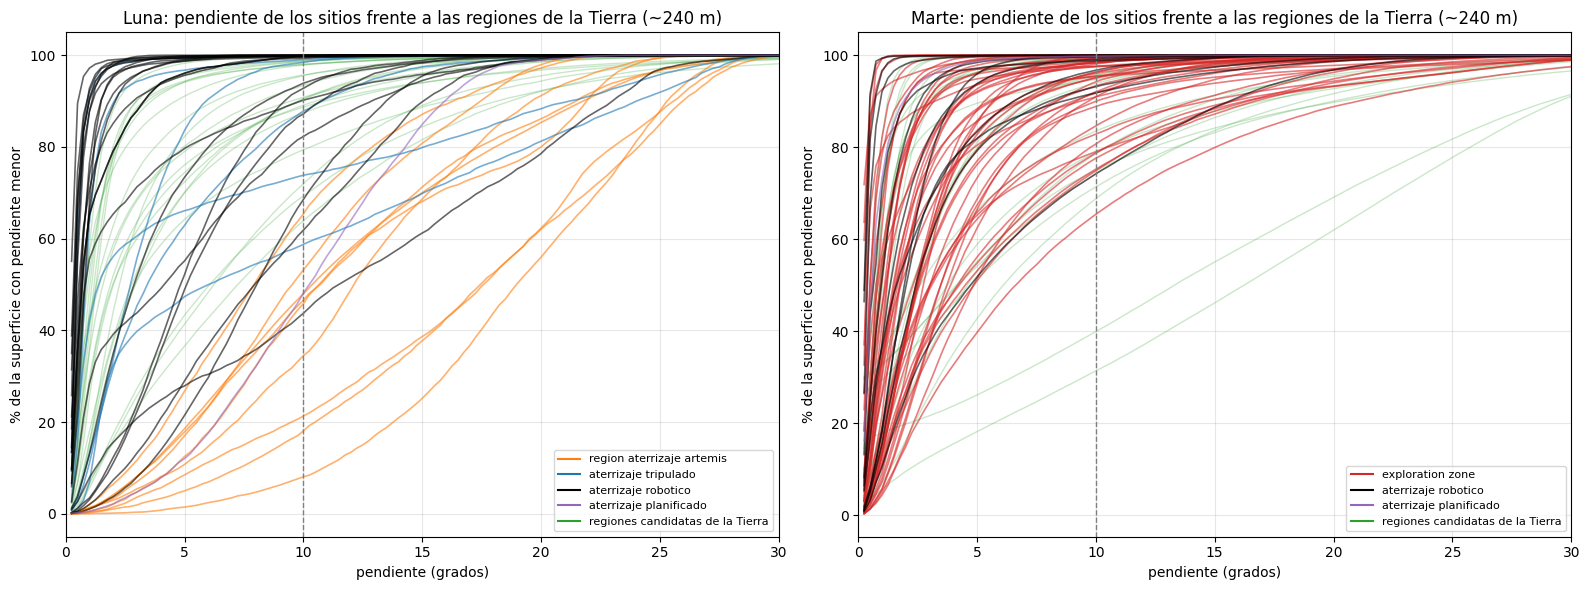

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
x = BINS[1:]
for ax, cuerpo in zip(axes, ["luna", "marte"]):
    for t in tierra[tierra.cuerpo == cuerpo].itertuples():
        ax.plot(x, cdf(H_T[t.region_id]) * 100, color="tab:green", alpha=0.25, lw=1)
    colores = {"region_aterrizaje_artemis": "tab:orange", "exploration_zone": "tab:red", "aterrizaje_tripulado": "tab:blue",
               "aterrizaje_robotico": "black", "aterrizaje_planificado": "tab:purple"}
    for tipo, color in colores.items():
        sel = sit[(sit.cuerpo == cuerpo) & (sit.tipo == tipo)]
        for r in sel.itertuples():
            if HIST[r.id].sum():
                ax.plot(x, cdf(HIST[r.id]) * 100, color=color, alpha=0.6, lw=1.2)
        if len(sel):
            ax.plot([], [], color=color, label=tipo.replace("_", " "))
    ax.plot([], [], color="tab:green", label="regiones candidatas de la Tierra")
    ax.axvline(10, color="grey", ls="--", lw=1); ax.set_xlim(0, 30); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax.set_xlabel("pendiente (grados)"); ax.set_ylabel("% de la superficie con pendiente menor")
    ax.set_title(f"{cuerpo.capitalize()}: pendiente de los sitios frente a las regiones de la Tierra (~240 m)")
plt.tight_layout(); plt.show()

## 7. Capa para la web y registro

In [18]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if np.isnan(v) else float(v)
    if isinstance(v, np.integer): return int(v)
    return v

salida = {"version": VERSION, "unidades": {"pendiente": "grados", "distancia_ks": "0–1, menor es más parecido"},
          "umbral_parecido": UMBRAL_PARECIDO,
          "sitios": {r["id"]: {**{k: limpio(v) for k, v in r.items() if k != "id"},
                               "top5_tierra": [{k: limpio(v) for k, v in p.items() if k != "sitio_id"}
                                               for p in top[top.sitio_id == r["id"]].to_dict("records")]}
                     for r in sit.to_dict("records")},
          "nota": "unir con 06_web/sitios_v0/sitios.geojson por id y con topografia_v0/topografia.json por region_id"}
json.dump(salida, open(f"{WEB}/topografia_sitios.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, allow_nan=False)
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
entrada.setdefault("capas", {})["topografia_sitios"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/topografia_sitios.json"}
json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
registro = {"version": VERSION, "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
            "datos": {"luna_polar": f"NASA LRO LOLA {PRODUCTO_POLAR} (PDS): {URL_P}", "luna": f"NASA LRO LOLA LDEM_128 (PDS): {URL_C}",
                      "marte": f"USGS HRSC–MOLA Blended DEM Global 200 m v2 (Fergason, Hare y Laura, 2018): {URL_MARTE}",
                      "tierra": "histogramas a ~240 m de topografia_v0 (NASA ASTER GDEM v3)"},
            "orientacion_polar": {"elegida": list(ORIENT), "correlacion": round(float(pruebas[ORIENT]), 3)},
            "parametros": {"radio_luna_km": RADIO_LUNA_KM, "radio_marte_km": RADIO_MARTE_KM, "umbral_parecido": UMBRAL_PARECIDO},
            "conteo": {"sitios": int(len(sit)), "regiones_tierra": int(len(tierra))},
            "limitaciones": ["solo pendiente: la comparación no incluye clima, materiales ni iluminación",
                             "Marte a 200 m y Tierra/Luna a ~240 m: escalas parecidas pero no idénticas",
                             "en regiones grandes de la Tierra solo se midió una parte (ver cobertura_teselas en topografia_v0)",
                             "las Exploration Zones se miden en un radio de 25 km alrededor de su centro, no en sus 100 km"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("topografia_sitios.json:", f"{os.path.getsize(f'{WEB}/topografia_sitios.json') / 1e3:.0f} KB", "| capas:", list(entrada["capas"]))

topografia_sitios.json: 111 KB | capas: ['cuevas', 'topografia', 'sitios', 'topografia_sitios']


## 8. Conclusiones
*Rellenar tras la ejecución.*